# MercaRAG — Experimento de chunking
Compara las tres estrategias con los **mismos documentos, las mismas 30 preguntas y las mismas condiciones** (protocolo de la sección 7.2 de la Entrega 1).

| Estrategia | Sugerido por el curso | Parámetros del grupo | Herramienta |
|---|---|---|---|
| Fixed-size | 256 tokens, overlap 32 | **256 tokens, overlap 32** (tokenizador de e5) | offsets del tokenizador del modelo |
| Sentence-aware | máx. 5 oraciones, overlap 1 | **5 oraciones, overlap 1**, tope 464 tokens | spaCy `es_core_news_sm` |
| Semantic | umbral coseno 0,75–0,85 | **umbral 0,80 fijo**, tope 464 tokens | spaCy + `multilingual-e5-small` |

**Reglas del protocolo**
1. Los parámetros están congelados en `mercarag/config.py`; aquí **no** se prueba ningún parámetro contra las métricas.
2. El conjunto de evaluación (`data/evaluacion/preguntas.csv`) se redactó antes de generar chunks: 30 preguntas con su *ground truth* y los documentos que las responden.
3. Mismo modelo de embeddings, `top_k = 5`, mismo LLM y prompt con temperatura 0, y el mismo juez para RAGAS.

**Hipótesis:** el semántico tendrá el mayor `context_recall` en fichas y manuales; en políticas, oraciones será igual o mejor; el fijo quedará último.

Requisito: haber ejecutado `01_rag_multimodal_mercarag.ipynb` hasta la sección 8 (documentos y chunks cargados).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mercarag import config, db, documentos, evaluacion
from mercarag.embeddings import Modelos

conn = db.get_connection()
modelos = Modelos()
docs = documentos.cargar_documentos()
print(f"{len(docs)} documentos")
for estrategia, params in config.PARAMETROS_CHUNKING.items():
    print(f"  {estrategia:10s} {params}")

93 documentos
  fijo       {'chunk_size': 256, 'chunk_overlap': 32}
  oraciones  {'max_sentences': 5, 'overlap': 1, 'spacy_model': 'es_core_news_sm', 'max_tokens': 464}
  semantico  {'threshold': 0.8, 'max_tokens': 464, 'min_tokens': 16}


## 1. Conjunto de evaluación
Se carga en `pregunta` (con su `ground_truth`) y `pregunta_documento` (documentos que contienen la respuesta). La carga es idempotente.

In [2]:
preguntas = evaluacion.cargar_conjunto_evaluacion(conn)
print(f"{len(preguntas)} preguntas")
display(preguntas.groupby("tipo").size().rename("preguntas").to_frame())
preguntas[["codigo_pregunta", "tipo", "texto_pregunta", "documentos"]].head(10)

30 preguntas


,preguntas
tipo,
ficha,7
guia,5
manual,7
multidocumento,3
politica,8


,codigo_pregunta,tipo,texto_pregunta,documentos
0,P01,politica,¿Cuánto cuesta el domicilio si mi pedido es de...,POL_DOMICILIOS
1,P02,politica,¿Hasta qué hora puedo pedir un domicilio un do...,POL_DOMICILIOS
2,P03,politica,¿Puedo cancelar un pedido que ya va en camino?,POL_DOMICILIOS
3,P04,politica,¿Cuántos días tengo para devolver un detergente?,POL_DEVOLUCIONES
4,P05,politica,"Pagué con tarjeta de crédito, ¿cuánto tarda el...",POL_DEVOLUCIONES
5,P06,politica,¿Qué me dan si me llega un producto vencido?,POL_DEVOLUCIONES
6,P07,politica,¿Se pueden acumular dos promociones en el mism...,POL_PROMOCIONES
7,P08,politica,¿Cuánto tiempo guardan mis datos de facturación?,POL_DATOS_PERSONALES
8,P09,manual,¿A qué temperatura se deben guardar los lácteo...,MAN_CADENA_FRIO
9,P10,manual,¿Por qué no se debe meter el banano en la nevera?,MAN_CADENA_FRIO


## 2. ¿Dónde corta el chunking semántico?
Cada oración se compara (coseno) con el **centroide** del chunk que se viene armando; si la similitud baja de **0,80** (fijo), la oración abre un chunk nuevo.
Este gráfico solo **muestra** las decisiones con el umbral ya fijado: no se usa para elegirlo.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

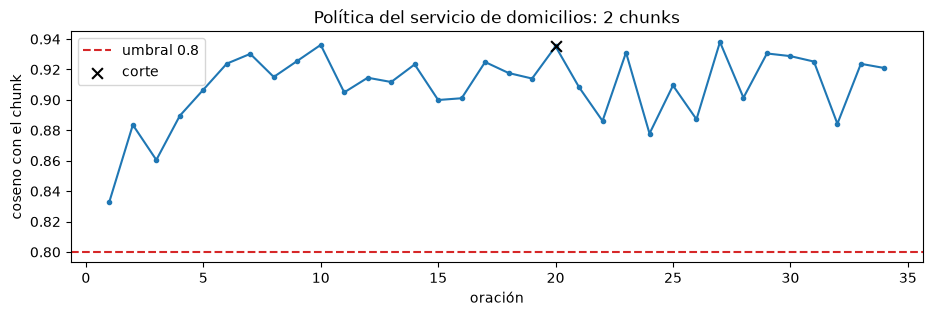

In [3]:
doc = next(d for d in docs if d["codigo_doc"] == "POL_DOMICILIOS")
oraciones, sims, cortes = evaluacion.similitudes_consecutivas(doc, modelos)
umbral = config.PARAMETROS_CHUNKING["semantico"]["threshold"]
x = np.arange(1, len(oraciones))
fig, eje = plt.subplots(figsize=(11, 3))
eje.plot(x, sims, marker="o", ms=3)
eje.axhline(umbral, ls="--", color="tab:red", label=f"umbral {umbral}")
c = [i for i in cortes if i > 0]
eje.scatter(c, sims[np.array(c) - 1] if c else [], marker="x", s=60, color="black", zorder=3, label="corte")
eje.set_xlabel("oración"); eje.set_ylabel("coseno con el chunk"); eje.set_title(f"{doc['titulo']}: {len(cortes)} chunks")
eje.legend(); plt.show()

## 3. Tamaño de los chunks
Todos los tamaños están en tokens del tokenizador de e5. La base rechaza cualquier chunk de más de 512 tokens (`CHECK`), así que **ninguno se trunca** al vectorizar.

In [4]:
stats = evaluacion.estadisticas_chunks(conn)
assert (stats["truncados"] == 0).all(), "Hay chunks que superan la ventana del modelo"
stats

,estrategia,chunks,documentos,chars_promedio,tokens_promedio,tokens_min,tokens_max,truncados
0,fijo,165,93,728,198,46,276,0
1,oraciones,381,93,360,105,57,184,0
2,semantico,104,93,1064,283,41,444,0


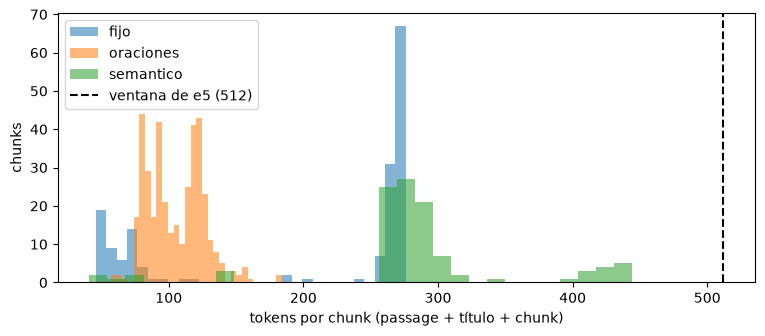

In [5]:
tokens = pd.DataFrame(db.consultar(conn, "SELECT estrategia_chunking AS estrategia, n_tokens FROM embeddings_texto", vectorial=False))
fig, eje = plt.subplots(figsize=(9, 3.5))
for estrategia in config.ESTRATEGIAS:
    eje.hist(tokens.loc[tokens.estrategia == estrategia, "n_tokens"], bins=30, alpha=0.55, label=estrategia)
eje.axvline(config.MAX_SEQ_TEXTO, color="black", ls="--", label="ventana de e5 (512)")
eje.set_xlabel("tokens por chunk (passage + título + chunk)"); eje.set_ylabel("chunks"); eje.legend(); plt.show()

## 4. Corridas: 30 preguntas × 3 estrategias
Cada corrida es un RAG completo (recuperar 5 chunks → generar) y queda en `consulta` (con `id_pregunta` y `estrategia_chunking`),
`resultado` (cada **chunk** con su posición y score) y `query_embeddings`. Una corrida que ya existe no se repite (`rehacer=True` la vuelve a hacer).
Sin `GROQ_API_KEY` se guarda la recuperación pero no la respuesta.

In [6]:
detalle = evaluacion.ejecutar_experimento(conn, modelos)
detalle.head()

Corridas nuevas: 0 | ya existentes: 90


,id_consulta,id_pregunta,codigo_pregunta,tipo_pregunta,estrategia_chunking,top_k,posicion_primer_acierto,hit_1,hit_k,reciprocal_rank,tiempo_recuperacion_ms,tiempo_total_ms,faithfulness,answer_relevancy,context_recall
0,3,1,P01,politica,fijo,5,1.0,1,1,1.0,55.87,1831.26,1.0,0.941,1.0
1,33,1,P01,politica,oraciones,5,1.0,1,1,1.0,28.12,7134.15,NaN,NaN,NaN
2,63,1,P01,politica,semantico,5,1.0,1,1,1.0,24.23,12330.83,NaN,NaN,NaN
3,4,2,P02,politica,fijo,5,1.0,1,1,1.0,45.93,861.07,0.5,0.943,1.0
4,34,2,P02,politica,oraciones,5,1.0,1,1,1.0,25.23,4826.22,NaN,NaN,NaN


## 5. Métricas RAGAS (faithfulness, answer_relevancy, context_recall)
Se calculan con las definiciones de RAGAS y un LLM juez sobre el contexto **exacto** que recibió el LLM (los chunks guardados en `resultado`).
Quedan en `evaluacion` (1:1 con la consulta). `context_recall` compara contra el `ground_truth` de cada pregunta.

In [ ]:
if config.GROQ_API_KEY:
    juez = evaluacion.Juez(espera_max_s=3600)
    detalle = evaluacion.evaluar_ragas(conn, modelos, juez=juez)

else:
    print("Sin GROQ_API_KEY: se reportan solo las métricas de recuperación (hit@1, hit@5, MRR)")

Límite de tokens: se espera 147 s y se reintenta
Límite de tokens: se espera 136 s y se reintenta
Límite de tokens: se espera 81 s y se reintenta
Límite de tokens: se espera 367 s y se reintenta
Límite de tokens: se espera 136 s y se reintenta
Límite de tokens: se espera 118 s y se reintenta
Límite de tokens: se espera 946 s y se reintenta
Límite de tokens: se espera 148 s y se reintenta
Límite de tokens: se espera 1 s y se reintenta
Límite de tokens: se espera 1005 s y se reintenta
Límite de tokens: se espera 147 s y se reintenta
Límite de tokens: se espera 353 s y se reintenta
Límite de tokens: se espera 141 s y se reintenta
Límite de tokens: se espera 372 s y se reintenta
Límite de tokens: se espera 26 s y se reintenta
Límite de tokens: se espera 102 s y se reintenta
Límite de tokens: se espera 1009 s y se reintenta
Límite de tokens: se espera 87 s y se reintenta
Límite de tokens: se espera 134 s y se reintenta
Límite de tokens: se espera 974 s y se reintenta
Límite de tokens: se es

## 6. Resultados por estrategia y por tipo de pregunta

In [ ]:
por_estrategia = evaluacion.resumen(detalle).reindex(list(config.ESTRATEGIAS))
display(por_estrategia)
por_tipo = evaluacion.resumen(detalle, ["tipo_pregunta", "estrategia_chunking"])
por_tipo

In [ ]:
columnas = [c for c in ["hit_1", "hit_k", "MRR", "faithfulness", "answer_relevancy", "context_recall"]
            if por_estrategia[c].notna().any()]
ax = por_estrategia[columnas].T.plot.bar(figsize=(10, 3.8), rot=0, ylim=(0, 1))
ax.set_title("Métricas por estrategia de chunking"); ax.set_ylabel("promedio")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.show()

## 7. ¿Las diferencias son significativas?
Prueba de Wilcoxon de rangos con signo, pareada por pregunta (α = 0,05). La hipótesis se rechaza si la diferencia de `context_recall` entre semántico y fijo no es significativa.

In [ ]:
metricas = ["context_recall", "faithfulness", "answer_relevancy"] if detalle["context_recall"].notna().any() else ["reciprocal_rank"]
pd.concat([evaluacion.prueba_wilcoxon(detalle, m) for m in metricas], ignore_index=True)

## 8. Guardar resultados

In [ ]:
config.RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)
stats.to_csv(config.RESULTADOS_DIR / "estadisticas_chunks.csv", index=False)
detalle.to_csv(config.RESULTADOS_DIR / "experimento_detalle.csv", index=False)
por_estrategia.to_csv(config.RESULTADOS_DIR / "experimento_por_estrategia.csv")
por_tipo.to_csv(config.RESULTADOS_DIR / "experimento_por_tipo.csv")
print("Guardado en", config.RESULTADOS_DIR)

## 9. Conclusión (completar con los resultados)
- **Mejor estrategia por `context_recall`:** …
- **¿Se cumplió la hipótesis?** (ver la prueba de Wilcoxon) …
- **Diferencias por tipo de pregunta** (fichas, políticas, manuales, guías, multidocumento): …
- **Latencia:** todas las recuperaciones deben estar por debajo de 1 s (requerimiento no funcional).

In [ ]:
conn.close()